# HOM unary

{'00101000': 15, '01000100': 3, '00010100': 4831, '00100010': 5, '10001000': 68, '01000001': 5050, '10000010': 28}
{'00010100': 4967, '01000001': 5033}
{'00010100': 5029, '01000001': 4971}
{'00010100': 5079, '01000001': 4921}
{'00010100': 4939, '01000001': 5061}
{'00010100': 4995, '01000001': 5005}


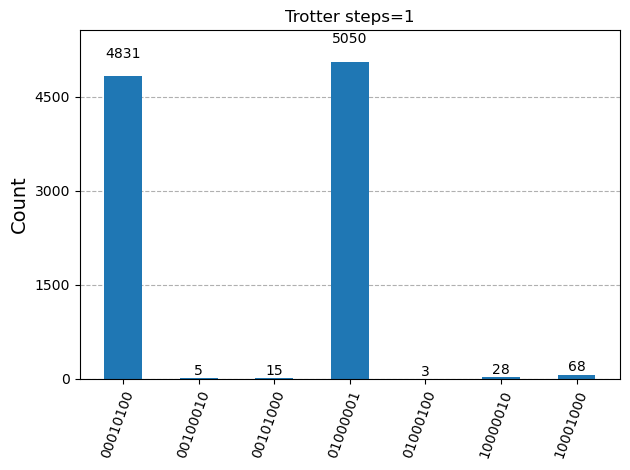

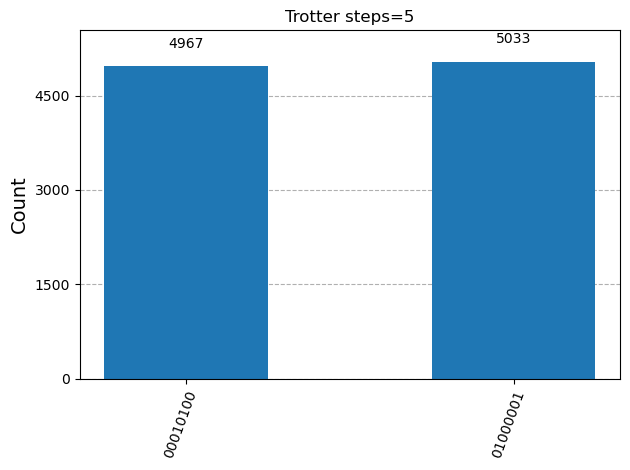

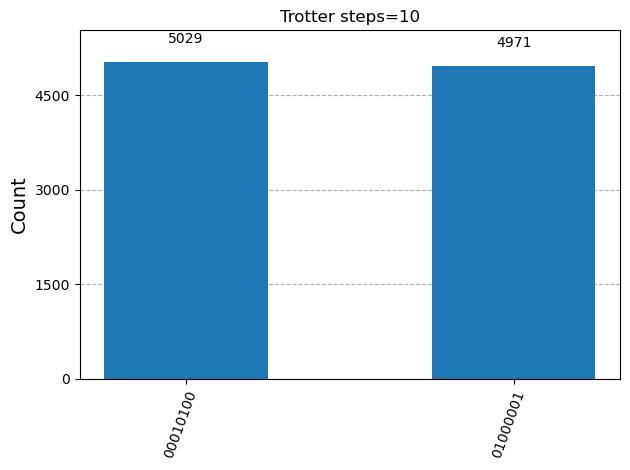

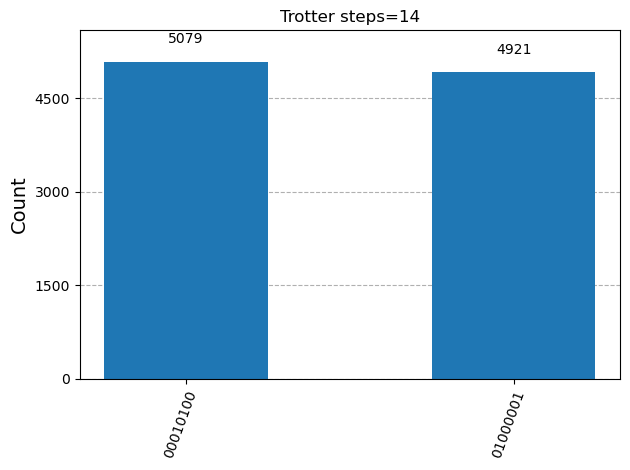

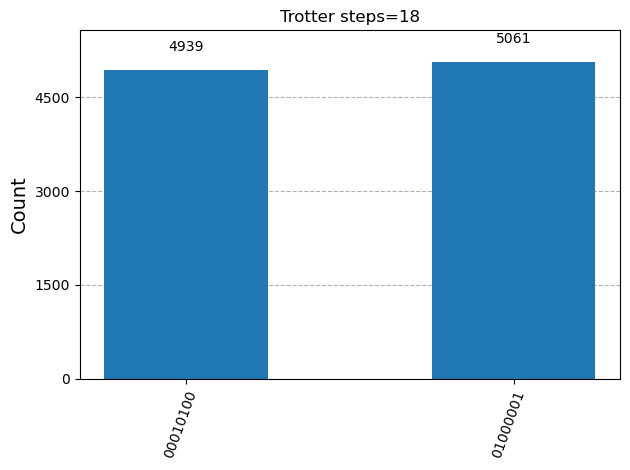

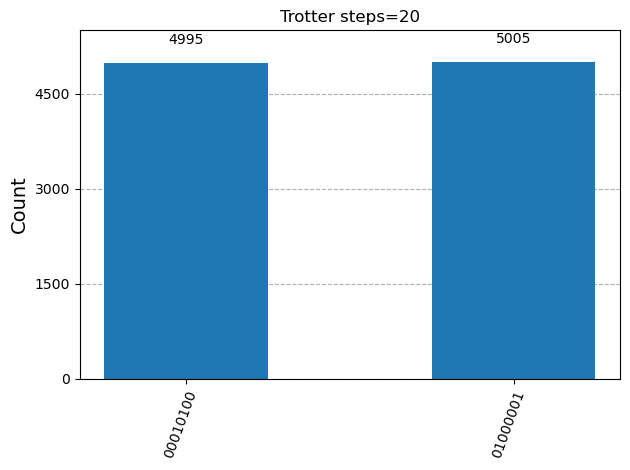

In [1]:
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import SparsePauliOp, Operator, Pauli
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.quantum_info import Operator
from qiskit.visualization import plot_histogram
from qiskit.synthesis import LieTrotter
from qiskit_aer import AerSimulator
from IPython.display import display, Math
import matplotlib.pyplot as plt
%matplotlib inline

X=Operator(Pauli("X")).data
Y=Operator(Pauli("Y")).data
Z=Operator(Pauli("Z")).data
I=np.eye(2,dtype=complex)

P_0=0.5*(I+Z)
P_1=0.5*(I-Z)

Q_0=0.5*(X+1j*Y)
Q_1=0.5*(X-1j*Y)

dag= np.kron(P_0,np.kron(P_0,(np.kron(Q_1,Q_0)))) + np.sqrt(2)* np.kron(P_0,np.kron(Q_1,(np.kron(Q_0,P_0))))+ np.sqrt(3)* np.kron(Q_1,np.kron(Q_0,(np.kron(P_0,P_0))))            

nor= np.kron(P_0,np.kron(P_0,(np.kron(Q_0,Q_1))))+ np.sqrt(2)* np.kron(P_0,np.kron(Q_0,(np.kron(Q_1,P_0)))) + np.sqrt(3)* np.kron(Q_0,np.kron(Q_1,(np.kron(P_0,P_0))))
                
I16=np.eye(16,dtype=complex)               
bdag= np.kron(I16,dag)
b=np.kron(I16,nor)

adag= np.kron(dag,I16)
a=np.kron(nor,I16)

H=np.pi/4*(bdag@a + b@adag)

H_P= SparsePauliOp.from_operator(Operator(H))
H_P=H_P.simplify()
#print(H_P)


def BScircuit(trotter_steps):
    qc=QuantumCircuit(8,8)
    qc.x(1)
    qc.x(5)
    evolution= PauliEvolutionGate(H_P,time=1,synthesis=LieTrotter(reps=trotter_steps),label="U_B")
    qc.append(evolution,[0,1,2,3,4,5,6,7])
    qc.measure(range(8),range(8))
    return qc

trotter_list=[1,5,10,14,18,20]
backend=AerSimulator()


for n in trotter_list:
    compiled_circuit=transpile(BScircuit(trotter_steps=n), backend)
    job = backend.run(compiled_circuit, shots=10000)
    
    result = job.result()
    counts = result.get_counts()
    print(counts)     
    plot_histogram(counts, title=f"Trotter steps={n}")

In [4]:
decomposed_circuit=BScircuit(1).decompose()
#decomposed_circuit.draw("mpl")
#plt.show()

In [5]:
print(decomposed_circuit.depth())

14783


In [6]:
print(decomposed_circuit.count_ops())

OrderedDict({'cx': 11520, 'h': 4608, 'sx': 2304, 'sxdg': 2304, 'rz': 1152, 'measure': 8, 'u': 2})
